# 03 · Impacto de negócio do score de propensão

> ⚠️ **Dados 100% simulados.** Todos os valores em reais e percentuais deste notebook vêm de uma base fictícia
> (`src/generate_data.py`, seed=42) e servem para ilustrar o método, não para representar uma empresa real.

**Pergunta de negócio:** se a empresa concentrar o esforço comercial e o remarketing **só nos 30% de leads com maior score**,
que fatia das conversões ela captura e quanto o custo por conversão (CPA) cai?

Usamos o **conjunto de teste** (7.500 leads que o modelo nunca viu) e o modelo final salvo em `models/modelo_xgboost.joblib`.

In [1]:
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

from src import train
from src.features import load_leads, split_data
from src.impact import (
    DEFAULT_EFFORT_COST, break_even_effort_cost, compare_focus, decile_table, gain_curve,
)
from src.plots import COLORS, save_figure, set_style

set_style()


def brl(valor: float) -> str:
    # Formata um valor em reais no padrão brasileiro (R$ 1.234).
    return "R$ " + f"{valor:,.0f}".replace(",", ".")


if not train.MODEL_PATH.exists():
    train.main()

_, _, X_test, _, _, y_test = split_data(load_leads())
modelo = joblib.load(train.MODEL_PATH)
scores = modelo.predict_proba(X_test)[:, 1]
custo_aquisicao = X_test["custo_aquisicao_lead"]
taxa_base = y_test.mean()

print(f"Teste: {len(y_test):,} leads | {y_test.sum()} conversões | taxa de {taxa_base:.1%}")

Teste: 7,500 leads | 302 conversões | taxa de 4.0%


## 1. Conversão por decil de score

Ordenamos os leads da maior para a menor probabilidade prevista e dividimos em 10 grupos iguais (decis). O decil 1 reúne os 10% com maior score.

In [2]:
decis = decile_table(y_test, scores)

tabela = decis[["leads", "conversoes", "taxa_conversao", "lift", "pct_conversoes_acum", "lift_acum"]].copy()
tabela.columns = ["Leads", "Conversões", "Taxa de conversão", "Lift", "% conversões acumuladas", "Lift acumulado"]
tabela.style.format({
    "Taxa de conversão": "{:.1%}", "Lift": "{:.2f}x", "% conversões acumuladas": "{:.1%}", "Lift acumulado": "{:.2f}x",
}).bar(subset=["Taxa de conversão"], color="#bcd4f2")

,Leads,Conversões,Taxa de conversão,Lift,% conversões acumuladas,Lift acumulado
decil,,,,,,
1,750,122,16.3%,4.04x,40.4%,4.04x
2,750,64,8.5%,2.12x,61.6%,3.08x
3,750,30,4.0%,0.99x,71.5%,2.38x
4,750,18,2.4%,0.60x,77.5%,1.94x
5,750,21,2.8%,0.70x,84.4%,1.69x
6,750,23,3.1%,0.76x,92.1%,1.53x
7,750,9,1.2%,0.30x,95.0%,1.36x
8,750,3,0.4%,0.10x,96.0%,1.20x
9,750,9,1.2%,0.30x,99.0%,1.10x


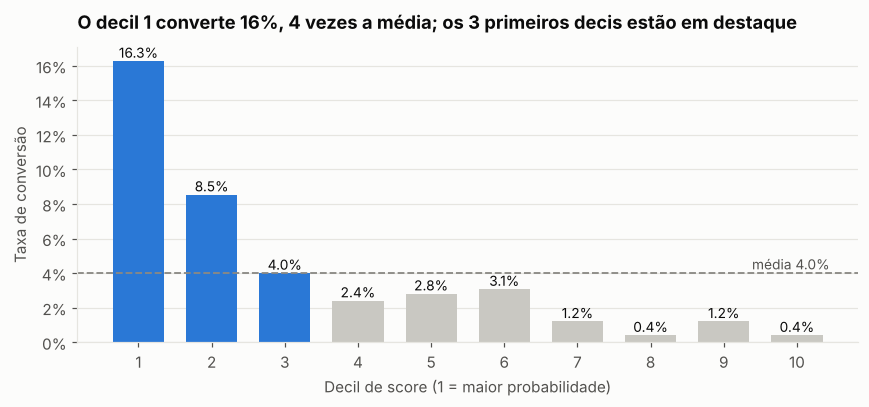

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.8))
cores = [COLORS["primary"] if d <= 3 else COLORS["muted_bar"] for d in decis.index]
ax.bar(decis.index.astype(str), decis["taxa_conversao"], color=cores, width=0.7)
ax.axhline(taxa_base, color=COLORS["reference"], linestyle="--", linewidth=1.2)
ax.text(9.5, taxa_base, f"média {taxa_base:.1%} ", ha="right", va="bottom", color=COLORS["text_secondary"], fontsize=9)
for i, valor in enumerate(decis["taxa_conversao"]):
    ax.text(i, valor + 0.002, f"{valor:.1%}", ha="center", fontsize=9)
ax.set_title("O decil 1 converte 16%, 4 vezes a média; os 3 primeiros decis estão em destaque")
ax.set_xlabel("Decil de score (1 = maior probabilidade)")
ax.set_ylabel("Taxa de conversão")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.grid(axis="x", visible=False)
fig.tight_layout()
save_figure(fig, "16_conversao_por_decil")
plt.show()

**Conclusão:** a conversão cai de forma quase monotônica ao longo dos decis: **16,3% no decil 1** contra 0,4% no decil 10, uma diferença de 40 vezes.
Só o decil 1 concentra **40% de todas as conversões**. A pequena oscilação nos decis 4 a 6 é ruído esperado com ~20 conversões por grupo.

## 2. Curva de ganho (gain)

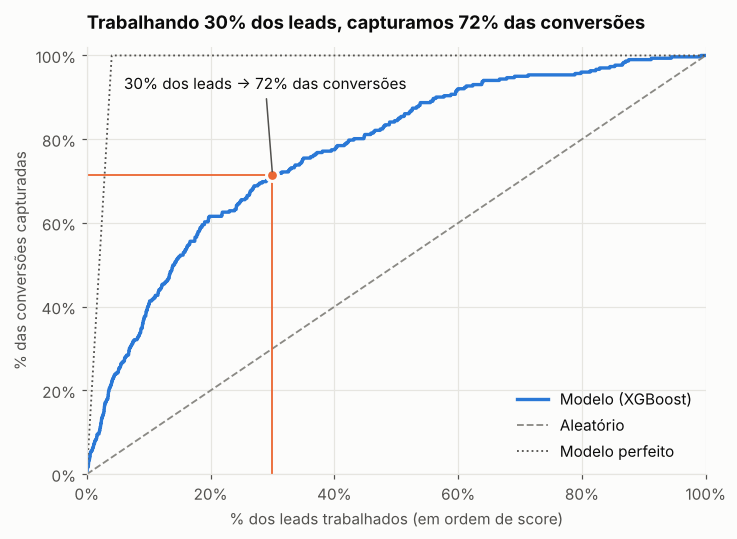

In [4]:
ganho = gain_curve(y_test, scores)
captura_30 = decis.loc[3, "pct_conversoes_acum"]

fig, ax = plt.subplots(figsize=(6.8, 5))
ax.plot(ganho["pct_leads"], ganho["pct_conversoes"], color=COLORS["primary"], linewidth=2.2, label="Modelo (XGBoost)")
ax.plot([0, 1], [0, 1], color=COLORS["reference"], linestyle="--", linewidth=1.2, label="Aleatório")
ax.plot([0, taxa_base, 1], [0, 1, 1], color=COLORS["text_secondary"], linestyle=":", linewidth=1.2, label="Modelo perfeito")
ax.plot([0.3, 0.3], [0, captura_30], color=COLORS["secondary"], linewidth=1.2)
ax.plot([0, 0.3], [captura_30, captura_30], color=COLORS["secondary"], linewidth=1.2)
ax.scatter([0.3], [captura_30], s=60, color=COLORS["secondary"], zorder=3, edgecolor=COLORS["surface"], linewidth=2)
ax.annotate(f"30% dos leads → {captura_30:.0%} das conversões", (0.3, captura_30), xytext=(0.06, 0.92),
            fontsize=10, color=COLORS["text"], arrowprops={"arrowstyle": "-", "color": COLORS["text_secondary"]})
ax.set(title="Trabalhando 30% dos leads, capturamos 72% das conversões",
       xlabel="% dos leads trabalhados (em ordem de score)", ylabel="% das conversões capturadas", xlim=(0, 1), ylim=(0, 1.02))
for eixo in (ax.xaxis, ax.yaxis):
    eixo.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.legend(loc="lower right")
fig.tight_layout()
save_figure(fig, "17_curva_ganho")
plt.show()

**Conclusão:** a curva do modelo fica bem acima da linha aleatória. Trabalhando os **30% de leads com maior score, a empresa captura 71,5% das
conversões**; escolhendo 30% ao acaso, capturaria só ~30%. A distância até a curva do "modelo perfeito" mostra o espaço que ainda existe para
melhorar com mais dados (por exemplo, eventos de navegação em tempo real).

## 3. Lift

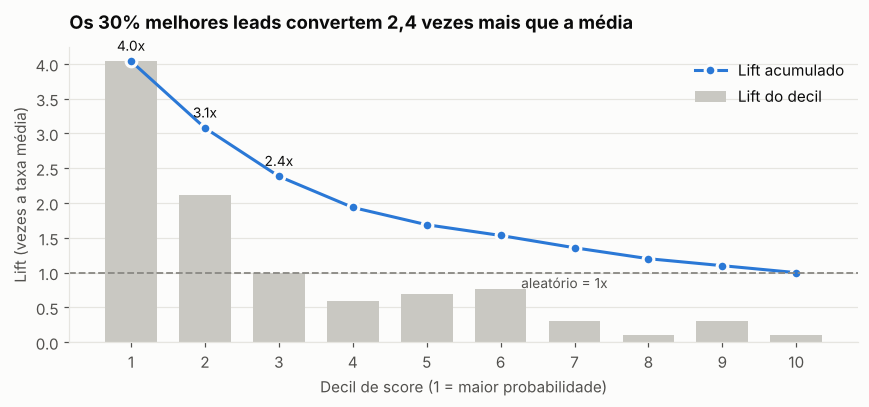

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(decis.index.astype(str), decis["lift"], color=COLORS["muted_bar"], width=0.7, label="Lift do decil")
ax.plot(decis.index.astype(str), decis["lift_acum"], color=COLORS["primary"], linewidth=2, marker="o", markersize=7,
        markeredgecolor=COLORS["surface"], markeredgewidth=2, label="Lift acumulado")
ax.axhline(1, color=COLORS["reference"], linestyle="--", linewidth=1.2)
ax.text(6.5, 0.97, "aleatório = 1x ", ha="right", va="top", color=COLORS["text_secondary"], fontsize=9)
for i, valor in enumerate(decis["lift_acum"].iloc[:3]):
    ax.text(i, valor + 0.15, f"{valor:.1f}x", ha="center", fontsize=9)
ax.set_title("Os 30% melhores leads convertem 2,4 vezes mais que a média")
ax.set_xlabel("Decil de score (1 = maior probabilidade)")
ax.set_ylabel("Lift (vezes a taxa média)")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
fig.tight_layout()
save_figure(fig, "18_lift_por_decil")
plt.show()

**Conclusão:** o **lift** compara a conversão de um grupo com a média. O decil 1 tem lift de **4,0x**, e os três primeiros decis juntos, **2,4x**.
A partir do decil 7, o lift fica abaixo de 0,3x: são leads em que cada real de esforço comercial rende muito pouco.

## 4. Cenário: focar esforço e remarketing nos 30% de maior score

### Premissas (explícitas e conservadoras)

| Premissa | Valor | Comentário |
|---|---|---|
| Custo de aquisição | o de cada lead (`custo_aquisicao_lead`) | Já foi gasto em mídia, e entra igual nos dois cenários. |
| Custo do esforço por lead trabalhado | **R$ 25** | Tempo de SDR (ligação + WhatsApp) e impressões de remarketing. É uma premissa, testada na seção 5. |
| Conversões fora do grupo trabalhado | **perdidas** | Conservador: na prática, parte desses leads compraria mesmo sem contato, então o ganho real tende a ser maior. |

**CPA = (custo de aquisição + custo do esforço) ÷ conversões.** Comparamos três cenários: trabalhar todos os leads (como hoje), trabalhar o top 30%
pelo modelo e, como controle, trabalhar 30% escolhidos ao acaso.

In [6]:
cenarios = compare_focus(y_test, scores, custo_aquisicao, fraction=0.30, effort_cost=DEFAULT_EFFORT_COST)

exibir = cenarios[["leads_trabalhados", "conversoes", "pct_conversoes_capturadas", "custo_esforco", "custo_total", "cpa", "variacao_cpa"]]
exibir.columns = ["Leads trabalhados", "Conversões", "% conversões", "Custo do esforço", "Custo total", "CPA", "Variação do CPA"]
exibir.style.format({
    "Leads trabalhados": lambda v: f"{v:,.0f}".replace(",", "."), "Conversões": "{:.0f}", "% conversões": "{:.1%}",
    "Custo do esforço": brl, "Custo total": brl, "CPA": brl, "Variação do CPA": "{:+.1%}",
})

,Leads trabalhados,Conversões,% conversões,Custo do esforço,Custo total,CPA,Variação do CPA
Todos os leads (atual),7.500,302,100.0%,R$ 187.500,R$ 272.974,R$ 904,+0.0%
Top 30% pelo modelo,2.250,216,71.5%,R$ 56.250,R$ 141.724,R$ 656,-27.4%
30% aleatórios,2.250,92,30.5%,R$ 56.250,R$ 141.724,R$ 1.540,+70.4%


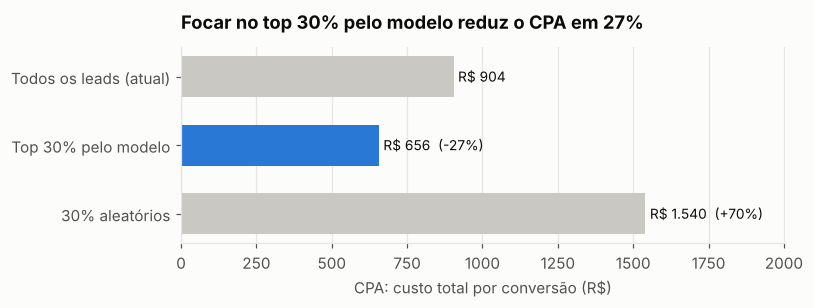

Conversões capturadas: 216 de 302 (71.5%)
CPA: R$ 904 → R$ 656 (-27.4%)
Custo do esforço por conversão: R$ 621 → R$ 260 (-58.1%)
Economia de esforço no teste: R$ 131.250 (70% menos leads trabalhados)


In [7]:
fig, ax = plt.subplots(figsize=(7.5, 2.9))
nomes = cenarios.index[::-1]
valores = cenarios["cpa"][::-1]
cores = [COLORS["primary"] if "modelo" in n else COLORS["muted_bar"] for n in nomes]
ax.barh(nomes, valores, color=cores, height=0.6)
for i, (valor, variacao) in enumerate(zip(valores, cenarios["variacao_cpa"][::-1])):
    rotulo = brl(valor) + ("" if variacao == 0 else f"  ({variacao:+.0%})")
    ax.text(valor + 15, i, rotulo, va="center", fontsize=9)
ax.set_title("Focar no top 30% pelo modelo reduz o CPA em 27%")
ax.set_xlabel("CPA: custo total por conversão (R$)")
ax.set_xlim(0, valores.max() * 1.3)
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_figure(fig, "19_cpa_cenarios")
plt.show()

atual, foco = cenarios.iloc[0], cenarios.iloc[1]
print(f"Conversões capturadas: {foco['conversoes']:.0f} de {atual['conversoes']:.0f} ({foco['pct_conversoes_capturadas']:.1%})")
print(f"CPA: {brl(atual['cpa'])} → {brl(foco['cpa'])} ({foco['variacao_cpa']:+.1%})")
print(f"Custo do esforço por conversão: {brl(atual['cpa_esforco'])} → {brl(foco['cpa_esforco'])} "
      f"({foco['cpa_esforco'] / atual['cpa_esforco'] - 1:+.1%})")
print(f"Economia de esforço no teste: {brl(atual['custo_esforco'] - foco['custo_esforco'])} (70% menos leads trabalhados)")

**Conclusão (dados simulados):**

- Trabalhando só os **30% de leads com maior score**, a empresa captura **71,5% das conversões** (216 de 302) com **30% do esforço**.
- O **CPA total cai 27%**, de **R$ 904 para R$ 656** por venda.
- O custo do esforço comercial por venda cai **58%**, de R$ 621 para R$ 260.
- Nos 7.500 leads do teste, a economia é de **R$ 131 mil** em esforço comercial e remarketing. Extrapolando para a base anual de 50 mil leads, seriam
  cerca de **R$ 875 mil**, que podem ser cortados ou reinvestidos em aquisição.
- **O mérito é do modelo, não do corte:** escolhendo 30% ao acaso, o CPA **subiria 70%**, porque a empresa perderia 70% das vendas sem ganho de eficiência.

**O custo dessa decisão:** na premissa conservadora, ~86 vendas (28%) deixam de acontecer. A decisão faz sentido se a margem dessas vendas for menor que a
economia gerada, ou se parte delas acontecer mesmo sem contato, o que é provável para leads de orgânico e e-mail.

## 5. Sensibilidade: e se o esforço por lead custar outro valor?

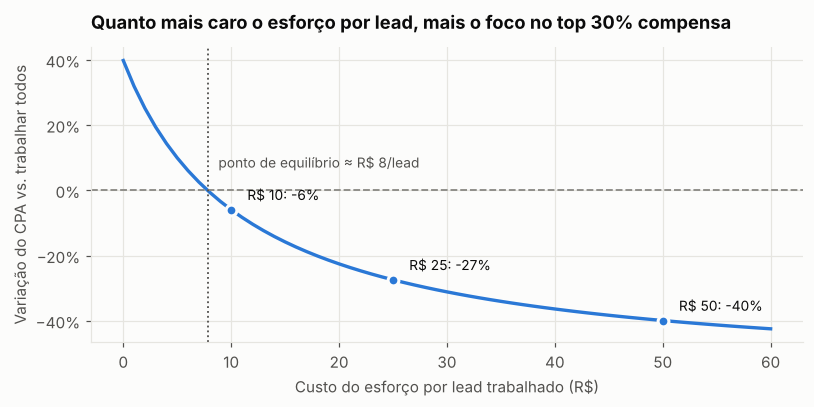

In [8]:
custos = np.arange(0, 61, 1)
variacoes = [
    compare_focus(y_test, scores, custo_aquisicao, effort_cost=c).iloc[1]["variacao_cpa"] for c in custos
]
equilibrio = break_even_effort_cost(y_test, scores, custo_aquisicao)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(custos, variacoes, color=COLORS["primary"], linewidth=2.2)
ax.axhline(0, color=COLORS["reference"], linestyle="--", linewidth=1.2)
ax.axvline(equilibrio, color=COLORS["text_secondary"], linestyle=":", linewidth=1.2)
ax.text(equilibrio + 1, 0.07, f"ponto de equilíbrio ≈ R$ {equilibrio:.0f}/lead", color=COLORS["text_secondary"], fontsize=9)
for c in [10, 25, 50]:
    v = variacoes[c]
    ax.scatter([c], [v], s=50, color=COLORS["primary"], zorder=3, edgecolor=COLORS["surface"], linewidth=2)
    ax.text(c + 1.5, v + 0.03, f"R$ {c}: {v:+.0%}", ha="left", fontsize=9)
ax.set_title("Quanto mais caro o esforço por lead, mais o foco no top 30% compensa")
ax.set_xlabel("Custo do esforço por lead trabalhado (R$)")
ax.set_ylabel("Variação do CPA vs. trabalhar todos")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
fig.tight_layout()
save_figure(fig, "20_sensibilidade_custo_esforco")
plt.show()

**Conclusão:** o resultado depende do custo do esforço por lead, e o notebook deixa isso transparente:

- Acima de **~R$ 8 por lead trabalhado**, focar no top 30% **reduz** o CPA: −6% a R$ 10, −27% a R$ 25 e −40% a R$ 50.
- Abaixo disso (por exemplo, um remarketing automático quase de graça), vale mais a pena **trabalhar todo mundo**, porque perder 28% das vendas sai mais caro
  que a economia. Nesse caso, o score serve para **diferenciar a abordagem** (ligação para o topo, e-mail automático para o resto), e não para excluir leads.

Como o custo real de um SDR fica bem acima de R$ 8 por lead, o foco no topo do ranking é a recomendação para o esforço comercial humano.

## Resumo executivo

> ⚠️ Resultados obtidos com **dados simulados**: ilustram o método, não uma empresa real.

| Indicador | Resultado no teste |
|---|---|
| Conversões capturadas trabalhando 30% dos leads | **71,5%** (vs. 30% ao acaso) |
| Lift dos 30% melhores leads | **2,4x** (decil 1: 4,0x) |
| CPA total (premissa de R$ 25 por lead trabalhado) | **R$ 904 → R$ 656 (−27%)** |
| Custo do esforço por venda | R$ 621 → R$ 260 (−58%) |
| Ponto de equilíbrio | o foco compensa a partir de ~R$ 8 por lead trabalhado |

**Recomendação:** usar o score para definir a fila do time comercial e o público de remarketing pago, concentrando-os nos 3 primeiros decis,
e manter uma nutrição automática e barata (e-mail) para os demais, para não perder as vendas que viriam sem contato.

**Limitações e próximos passos:**
- A premissa de "conversões perdidas" é conservadora. Um **teste A/B** (grupo trabalhado pelo score vs. grupo controle) mediria o ganho real e causal.
- O cálculo usa custo, não receita. Com o ticket médio e a margem dos cursos, dá para otimizar o corte pelo **lucro**, e não só pelo CPA.
- Leads com score alto podem comprar mesmo sem contato. Um **modelo de uplift** identificaria quem compra **por causa** do contato.